# Forzy - Challenge Sprint 4: Governança do Produto Analítico (notebook técnico)

**FIAP - Governança em IA** | Octavio Augusto Ramalho Brandão Pires - RM 555696

Este notebook complementa o documento da Sprint 4 e demonstra, em código, os itens de governança que a documentação descreve:

| Seção do notebook | Seção do documento |
|---|---|
| 1. Metric Contract em YAML e Linter Semântico | 8 e Apêndice A, 13.3 |
| 2. Motor de classificação e Circuit Breaker (v1.0.0 x v1.1.0) | 9 |
| 3. Incidente simulado: sensor de temperatura enviando zeros por 2 horas | 14.3 |
| 4. Gates de Promoção (MAT, Golden Dataset, Linter, segredos) | 13.3 |
| 5. Assistente conversacional governado (RBAC, citação de fonte, log de auditoria) | 11 e 4.3 |
| 6. SLOs, Error Budget e Painel de Observabilidade | 14 e 15 |

**Aviso:** todos os dados (telemetria, documentos, usuários e decisões) são **simulados**. Não há LLM nem integração IoT real: a geração de texto do assistente é por template, para isolar e demonstrar os controles de governança.

In [1]:
import os, re, json, uuid, hashlib, hmac, secrets
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
import unicodedata

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
SEED = 42
print("Ambiente pronto. Seed fixa =", SEED)

Ambiente pronto. Seed fixa = 42


## 1. Metric Contract (YAML, versão 1.1.0) e Linter Semântico

O contrato é versionado com SemVer e possui `changelog`. Em produção ele vive no repositório (`metric_contract.yaml`); aqui está embutido para o notebook rodar sem arquivos externos.

In [2]:
CONTRACT_YAML = r"""
# =====================================================================
# Metric Contract - Plataforma Forzy
# Versionamento semantico (MAJOR.MINOR.PATCH). Ver bloco "changelog".
#   MAJOR: altera threshold critico, remove/renomeia sensor, muda semantica
#          de classe ou escopo de perfil (exige Banner de Ruptura + rollback)
#   MINOR: adiciona sensor, regra ou campo sem alterar o que ja existe
#   PATCH: correcao de texto, comentario ou documentacao
# =====================================================================
contract:
  name: forzy-metric-contract
  version: "1.1.0"
  status: active
  last_updated: "2026-11-26"
  approver_role: "Engenheiro de Confiabilidade"
  maintainer_role: "Data Product Owner"
  breaking_change_policy: "MAJOR exige Banner de Ruptura e plano de rollback"

reference_asset:
  description: "Motor de inducao trifasico 45 kW, acoplado rigidamente a bomba centrifuga, base rigida"
  iso_class: "II (ISO 10816-3 / ISO 20816-1)"
  ambient_reference_c: 25
  tag_pattern: "^MOT-[0-9]{3}-[A-Z]{3}$"
  example_tag: "MOT-001-SBC"
  legacy_asset_tolerance_critical_pct: 10

profiles:
  - "Operador de Manutenção"
  - "Engenheiro de Confiabilidade"
  - "Auditor de Governança/TI"
  - "Data Scientist (Admin)"

sensors:
  vibracao:
    unit: "mm/s"
    measure: "RMS"
    warning: 4.5
    critical: 7.1
    reference: "ISO 10816-3 / ISO 20816-1, Classe II, 15-75 kW"
    auto_action_warning: "registrar_alerta_e_aumentar_frequencia_de_amostragem"
    auto_action_critical: "alerta_critico_e_notificacao_obrigatoria"
    plausible_range: [0.05, 50.0]
    max_jump: 5.0
  temperatura:
    unit: "degC"
    measure: "carcaca"
    warning: 75.0
    critical: 95.0
    reference: "SKF / ISO 15243; isolamento Classe F (IEC 60034-1) com margem para o mancal"
    auto_action_warning: "registrar_alerta_e_notificar_manutencao_preditiva"
    auto_action_critical: "alerta_critico_e_notificacao_obrigatoria"
    plausible_range: [5.0, 150.0]
    max_jump: 25.0
  aceleracao:
    unit: "g"
    measure: "envelope_pico"
    warning: 2.0
    critical: 3.5
    reference: "Baseline de fabrica do ativo + fator de seguranca"
    auto_action_warning: "alerta_imediato"
    auto_action_critical: "alerta_imediato_e_sinalizar_possivel_falha_estrutural"
    plausible_range: [0.01, 20.0]
    max_jump: 3.0

anomaly:
  method: "zscore"
  zscore_threshold: 3.0
  min_history: 5
  history_window: 10

circuit_breaker:
  window: 10
  max_missing_pct: 30
  redundant_sensor_divergence_pct: 20
  state_after_trigger: "HALF_OPEN"
  valid_readings_to_close: 3
  rules:
    missing_data:        {since: "1.0.0"}
    implausible_jump:    {since: "1.0.0"}
    redundant_divergence: {since: "1.0.0"}
    out_of_range:        {since: "1.1.0"}
    flatline:            {since: "1.1.0", window: 10, epsilon: 0.01}

handoff:
  anomaly_review_deadline_hours: 2
  sensor_offline_deadline_minutes: 30
  offline_trigger_consecutive_readings: 3
  notification:
    warning: ["painel"]
    critical: ["painel", "sms_push"]
  autonomous_actions: ["monitorar", "registrar_alerta_warning", "aumentar_frequencia_amostragem"]
  human_approval_required: ["parada_de_motor", "troca_de_componente", "ajuste_de_threshold"]
  ai_can_shutdown_motor: false

assistant:
  citation_required: true
  min_retrieval_score: 0.20
  no_source_route: "revisao_humana"
  decisions_allowed: ["aceitou", "rejeitou", "escalou"]
  audit_fields:
    - trace_id
    - timestamp_utc
    - perfil_usuario_pseudonimizado
    - documentos_recuperados
    - versao_modelo_linguagem
    - versao_base_conhecimento
    - versao_modelo_ml
    - decisao_operador
  log_redaction: ["token", "senha", "authorization", "api_key"]

slo:
  window_days: 30
  freshness_p95_seconds: 300
  freshness_critical_alert_p95_seconds: 60
  completeness_pct: 98.0
  precision_critical_pct: 90.0
  precision_warning_pct: 75.0
  availability_effective_pct: 99.5

changelog:
  - version: "1.1.0"
    date: "2026-11-26"
    type: "MINOR"
    changes:
      - "Adiciona regras de Circuit Breaker out_of_range e flatline (acao corretiva do INC-2026-001)"
      - "Adiciona plausible_range por sensor"
      - "Adiciona blocos handoff, assistant e slo"
      - "Padroniza TAG de exemplo como MOT-001-SBC"
      - "Nao altera thresholds nem classes de leitura (por isso MINOR)"
  - version: "1.0.0"
    date: "2026-08-31"
    type: "MAJOR"
    changes:
      - "Versao inicial formalizada na Sprint 3: thresholds de vibracao, temperatura e aceleracao"
      - "Circuit Breaker com janela, percentual de faltantes e salto implausivel"
      - "Deteccao estatistica por z-score"
"""

contract = yaml.safe_load(CONTRACT_YAML)
with open("metric_contract.yaml", "w", encoding="utf-8") as f:
    f.write(CONTRACT_YAML)
print("Contrato carregado:", contract["contract"]["name"], "v" + contract["contract"]["version"])
pd.DataFrame(contract["sensors"]).T[["unit", "warning", "critical", "plausible_range", "max_jump"]]

Contrato carregado: forzy-metric-contract v1.1.0


,unit,warning,critical,plausible_range,max_jump
vibracao,mm/s,4.5,7.1,"[0.05, 50.0]",5.0
temperatura,degC,75.0,95.0,"[5.0, 150.0]",25.0
aceleracao,g,2.0,3.5,"[0.01, 20.0]",3.0


In [3]:
# Linter Semantico: valida coerencia do contrato antes de qualquer promocao (Gate 3)
SEMVER = re.compile(r"^\d+\.\d+\.\d+$")
GLOSSARIO_PERFIS = ["Operador de Manutenção", "Engenheiro de Confiabilidade",
                    "Auditor de Governança/TI", "Data Scientist (Admin)"]
UNIDADES_VALIDAS = {"mm/s", "degC", "g"}

def linter_semantico(c):
    erros = []
    if not SEMVER.match(str(c["contract"]["version"])):
        erros.append("versao fora do padrao SemVer")
    for nome, s in c["sensors"].items():
        lo, hi = s["plausible_range"]
        if s["unit"] not in UNIDADES_VALIDAS:
            erros.append(f"{nome}: unidade invalida ({s['unit']})")
        if not s["warning"] < s["critical"]:
            erros.append(f"{nome}: warning deve ser menor que critical")
        if not (lo < s["warning"] < s["critical"] <= hi):
            erros.append(f"{nome}: thresholds fora da faixa plausivel")
        if s["max_jump"] <= 0:
            erros.append(f"{nome}: max_jump deve ser positivo")
    ra = c["reference_asset"]
    if not re.match(ra["tag_pattern"], ra["example_tag"]):
        erros.append("TAG de exemplo nao segue o padrao de TAG")
    if c["circuit_breaker"]["valid_readings_to_close"] < 1:
        erros.append("valid_readings_to_close deve ser >= 1")
    if set(c["profiles"]) != set(GLOSSARIO_PERFIS):
        erros.append("perfis divergem do glossario (mesmos perfis das Sprints 1 a 3)")
    if c["changelog"][0]["version"] != c["contract"]["version"]:
        erros.append("topo do changelog difere da versao do contrato")
    if c["slo"]["availability_effective_pct"] >= 100:
        erros.append("SLO de disponibilidade em 100% nao gera error budget")
    return erros

erros_linter = linter_semantico(contract)
print("Linter Semantico:", "APROVADO" if not erros_linter else "REPROVADO")
for e in erros_linter:
    print(" -", e)

Linter Semantico: APROVADO


## 2. Motor de classificação e Circuit Breaker

`avaliar_sensor` aplica o contrato a uma série de leituras. O parâmetro `versao_regras` permite comparar o comportamento da **v1.0.0** (Sprint 3) com a **v1.1.0** (Sprint 4), que adiciona as regras `fora_da_faixa` e `flatline`.

Máquina de estados: `CLOSED` → (incerteza) → `OPEN` → (leitura sem incerteza) → `HALF_OPEN` → (3 leituras válidas consecutivas) → `CLOSED`. Qualquer incerteza em `HALF_OPEN` retorna a `OPEN` e zera o contador.

In [4]:
def _vtuple(v):
    return tuple(int(x) for x in v.split("."))

def _falt(x):
    return x is None or (isinstance(x, float) and np.isnan(x))

def avaliar_sensor(valores, sensor, contrato, versao_regras="1.1.0", ativo_legado=False):
    s, cb, an = contrato["sensors"][sensor], contrato["circuit_breaker"], contrato["anomaly"]
    warn, crit = s["warning"], s["critical"]
    if ativo_legado:  # tolerancia de 10% apenas para o limiar critico (Sprint 1)
        crit = crit * (1 + contrato["reference_asset"]["legacy_asset_tolerance_critical_pct"] / 100)
    novo = _vtuple(versao_regras) >= (1, 1, 0)
    vals = list(valores)
    estado, validas, hist_ok, linhas = "CLOSED", 0, [], []
    for i, v in enumerate(vals):
        motivos = []
        faltante = _falt(v)
        janela = vals[max(0, i - cb["window"] + 1): i + 1]
        pct = 100 * np.mean([_falt(x) for x in janela])
        if faltante:
            motivos.append("dado_faltante")
        elif pct > cb["max_missing_pct"]:
            motivos.append("janela_com_faltantes")
        if not faltante and i > 0 and not _falt(vals[i - 1]) and abs(v - vals[i - 1]) > s["max_jump"]:
            motivos.append("salto_implausivel")
        if novo and not faltante:
            lo, hi = s["plausible_range"]
            if v < lo or v > hi:
                motivos.append("fora_da_faixa")
            fl = cb["rules"]["flatline"]
            w = vals[max(0, i - fl["window"] + 1): i + 1]
            if len(w) == fl["window"] and not any(_falt(x) for x in w) and (max(w) - min(w)) <= fl["epsilon"]:
                motivos.append("flatline")
        if motivos:
            estado, validas, liberado = "OPEN", 0, False
        elif estado == "CLOSED":
            liberado = True
        else:
            validas += 1
            if validas >= cb["valid_readings_to_close"]:
                estado, validas, liberado = "CLOSED", 0, True
            else:
                estado, liberado = "HALF_OPEN", False
        if faltante:
            classe = "SEM_DADO"
        else:
            classe = "CRITICAL" if v >= crit else ("WARNING" if v >= warn else "NORMAL")
            if classe == "NORMAL" and liberado and len(hist_ok) >= an["min_history"]:
                h = hist_ok[-an["history_window"]:]
                sd = np.std(h, ddof=1)
                if sd > 0 and abs(v - np.mean(h)) / sd >= an["zscore_threshold"]:
                    classe = "ANOMALIA_ESTATISTICA"
        if not motivos and not faltante:
            hist_ok.append(v)
        linhas.append(dict(idx=i, valor=v, classe=classe, estado_breaker=estado,
                           motivos=",".join(motivos), alerta_liberado=liberado,
                           alerta_final=classe if liberado else "TRAVADO_CIRCUIT_BREAKER"))
    return pd.DataFrame(linhas)

# Verificacao rapida com o trecho da Sprint 3 (amostras 20-25 travadas, liberacao na 26)
rng = np.random.default_rng(SEED)
serie = list(2.2 + rng.normal(0, 0.1, 30))
serie[10:15] = [15.0, 0.1, 14.0, 2.25, 2.40]
df_s3 = avaliar_sensor(serie, "vibracao", contrato=contract, versao_regras="1.0.0")
df_s3.iloc[8:18][["idx", "valor", "classe", "estado_breaker", "alerta_liberado", "alerta_final"]]

,idx,valor,classe,estado_breaker,alerta_liberado,alerta_final
8,8,2.198320,NORMAL,CLOSED,True,NORMAL
9,9,2.114696,NORMAL,CLOSED,True,NORMAL
10,10,15.000000,CRITICAL,OPEN,False,TRAVADO_CIRCUIT_BREAKER
11,11,0.100000,NORMAL,OPEN,False,TRAVADO_CIRCUIT_BREAKER
12,12,14.000000,CRITICAL,OPEN,False,TRAVADO_CIRCUIT_BREAKER
13,13,2.250000,NORMAL,OPEN,False,TRAVADO_CIRCUIT_BREAKER
14,14,2.400000,NORMAL,HALF_OPEN,False,TRAVADO_CIRCUIT_BREAKER
15,15,2.114071,NORMAL,HALF_OPEN,False,TRAVADO_CIRCUIT_BREAKER
16,16,2.236875,NORMAL,CLOSED,True,NORMAL
17,17,2.104112,NORMAL,CLOSED,True,NORMAL


In [5]:
# Limitacao medida: taxa de falsos positivos da regra z-score >= 3 em ruido puro (janela de 10 leituras)
r_fp = np.random.default_rng(0)
saida_fp = avaliar_sensor(list(2.2 + r_fp.normal(0, 0.1, 20000)), "vibracao", contract)
taxa_fp = (saida_fp["classe"] == "ANOMALIA_ESTATISTICA").mean()
print(f"Falsos positivos da deteccao estatistica em operacao normal: {100 * taxa_fp:.2f}% das leituras")

Falsos positivos da deteccao estatistica em operacao normal: 1.85% das leituras


## 3. Incidente simulado INC-2026-001: sensor de temperatura enviando zeros por 2 horas

Cenário: leituras por minuto entre 13:00 e 17:00 (UTC) do MOT-001-SBC. Entre 14:00 e 15:59 o sensor de temperatura passa a enviar `0.0`. A mesma série é avaliada com as regras da **v1.0.0** e da **v1.1.0**.

In [6]:
rng = np.random.default_rng(SEED)
t = pd.date_range("2026-11-10 13:00", periods=240, freq="min", tz="UTC")
temp = 71 + 0.4 * np.sin(np.linspace(0, 6, 240)) + rng.normal(0, 0.3, 240)
mascara_invalida = np.zeros(240, dtype=bool)
mascara_invalida[60:180] = True            # 14:00 a 15:59 (120 leituras)
temp_defeito = np.where(mascara_invalida, 0.0, temp)

r100 = avaliar_sensor(list(temp_defeito), "temperatura", contract, versao_regras="1.0.0")
r110 = avaliar_sensor(list(temp_defeito), "temperatura", contract, versao_regras="1.1.0")

def invalido_servido_como_normal(r):
    return int(((mascara_invalida) & (r["alerta_final"] != "TRAVADO_CIRCUIT_BREAKER")).sum())

min_100, min_110 = invalido_servido_como_normal(r100), invalido_servido_como_normal(r110)
primeira_liberacao = r100[(mascara_invalida) & (r100["alerta_liberado"])].idx.min()
resumo = pd.DataFrame({
    "regras": ["v1.0.0 (Sprint 3)", "v1.1.0 (Sprint 4)"],
    "leituras_invalidas_servidas_como_NORMAL": [min_100, min_110],
    "minutos_de_dado_invalido_exibido": [min_100, min_110],
})
print("Na v1.0.0 o breaker reabriu na leitura de indice", primeira_liberacao,
      "(horario", t[primeira_liberacao].strftime("%H:%M"), "UTC), pois zeros constantes nao geram salto nem dado faltante.")
resumo

Na v1.0.0 o breaker reabriu na leitura de indice 63 (horario 14:03 UTC), pois zeros constantes nao geram salto nem dado faltante.


,regras,leituras_invalidas_servidas_como_NORMAL,minutos_de_dado_invalido_exibido
0,v1.0.0 (Sprint 3),117,117
1,v1.1.0 (Sprint 4),0,0


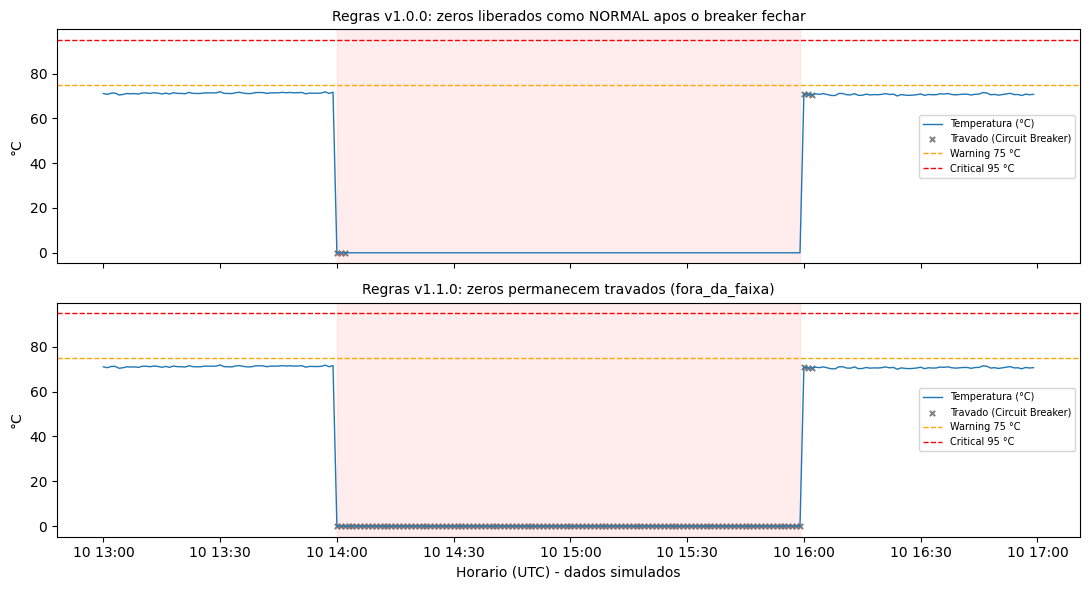

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, r, titulo in [(ax[0], r100, "Regras v1.0.0: zeros liberados como NORMAL apos o breaker fechar"),
                     (ax[1], r110, "Regras v1.1.0: zeros permanecem travados (fora_da_faixa)")]:
    a.plot(t, r["valor"], lw=1, color="tab:blue", label="Temperatura (°C)")
    trav = r["alerta_final"] == "TRAVADO_CIRCUIT_BREAKER"
    a.scatter(t[trav], r.loc[trav, "valor"], marker="x", color="gray", s=14, label="Travado (Circuit Breaker)")
    a.axhline(75, ls="--", color="orange", lw=1, label="Warning 75 °C")
    a.axhline(95, ls="--", color="red", lw=1, label="Critical 95 °C")
    a.axvspan(t[60], t[179], color="red", alpha=0.07)
    a.set_title(titulo, fontsize=10); a.set_ylabel("°C"); a.legend(loc="center right", fontsize=7)
plt.xlabel("Horario (UTC) - dados simulados"); plt.tight_layout(); plt.show()

## 4. Gates de Promoção

Uma nova versão do contrato/motor só é promovida se passar nos quatro gates: **MAT**, **Regressão contra Golden Dataset**, **Linter Semântico** e **varredura de segredos**. O padrão de resiliência adotado é o **Canary Deploy** (descrito no documento, seção 13.4).

In [8]:
# Gate 1 - MAT (teste de aceitacao das metricas do Metric Contract)
casos_mat = [  # (sensor, valor, ativo_legado, classe_esperada)
    ("vibracao", 2.0, False, "NORMAL"), ("vibracao", 4.5, False, "WARNING"),
    ("vibracao", 7.09, False, "WARNING"), ("vibracao", 7.1, False, "CRITICAL"),
    ("vibracao", 7.5, True, "WARNING"), ("vibracao", 7.9, True, "CRITICAL"),
    ("temperatura", 74.9, False, "NORMAL"), ("temperatura", 75.0, False, "WARNING"),
    ("temperatura", 95.0, False, "CRITICAL"),
    ("aceleracao", 1.99, False, "NORMAL"), ("aceleracao", 2.0, False, "WARNING"),
    ("aceleracao", 3.5, False, "CRITICAL"),
]
linhas = []
for sensor, valor, leg, esperado in casos_mat:
    obtido = avaliar_sensor([valor], sensor, contract, ativo_legado=leg).loc[0, "classe"]
    linhas.append(dict(sensor=sensor, valor=valor, ativo_legado=leg, esperado=esperado, obtido=obtido, ok=obtido == esperado))
mat = pd.DataFrame(linhas)
gate_mat = bool(mat["ok"].all())
print("Gate MAT:", "APROVADO" if gate_mat else "REPROVADO", f"({mat['ok'].sum()}/{len(mat)} casos)")
mat

Gate MAT: APROVADO (12/12 casos)


,sensor,valor,ativo_legado,esperado,obtido,ok
0,vibracao,2.00,False,NORMAL,NORMAL,True
1,vibracao,4.50,False,WARNING,WARNING,True
2,vibracao,7.09,False,WARNING,WARNING,True
3,vibracao,7.10,False,CRITICAL,CRITICAL,True
4,vibracao,7.50,True,WARNING,WARNING,True
5,vibracao,7.90,True,CRITICAL,CRITICAL,True
6,temperatura,74.90,False,NORMAL,NORMAL,True
7,temperatura,75.00,False,WARNING,WARNING,True
8,temperatura,95.00,False,CRITICAL,CRITICAL,True
9,aceleracao,1.99,False,NORMAL,NORMAL,True


In [9]:
# Gate 2 - Regressao contra Golden Dataset (casos congelados e aprovados; oraculos independentes do motor)
def golden_cases():
    g = {}
    r = np.random.default_rng(2)
    g["G1_operacao_normal"] = dict(sensor="vibracao", serie=list(2.2 + r.normal(0, 0.1, 40)))
    r = np.random.default_rng(SEED)
    s = list(2.2 + r.normal(0, 0.1, 30)); s[10:15] = [15.0, 0.1, 14.0, 2.25, 2.40]
    g["G2_dados_ruins_sprint3"] = dict(sensor="vibracao", serie=s)
    r = np.random.default_rng(3)
    s = list(2.2 + r.normal(0, 0.1, 20)) + list(np.linspace(2.8, 8.4, 11)) + [8.4] * 4
    g["G3_degradacao_real"] = dict(sensor="vibracao", serie=s)
    g["G4_temperatura_zeros"] = dict(sensor="temperatura", serie=[71.0 + 0.3 * ((i * 7) % 5 - 2) / 2 for i in range(30)] + [0.0] * 40 + [71.0 + 0.1 * (i % 3) for i in range(10)])
    r = np.random.default_rng(5)
    g["G5_flatline_valor_plausivel"] = dict(sensor="temperatura", serie=list(72 + r.normal(0, 0.3, 20)) + [71.30] * 25)
    return g

def checar_golden(versao):
    g, res = golden_cases(), {}
    for nome, c in g.items():
        r = avaliar_sensor(c["serie"], c["sensor"], contract, versao_regras=versao)
        fin, v = r["alerta_final"], r["valor"]
        if nome == "G1_operacao_normal":
            ok = bool((fin == "NORMAL").all())
        elif nome == "G2_dados_ruins_sprint3":
            ok = list(r.index[fin == "TRAVADO_CIRCUIT_BREAKER"]) == [10, 11, 12, 13, 14, 15]
        elif nome == "G3_degradacao_real":
            crit_idx = [i for i, x in enumerate(c["serie"]) if x >= 7.1]
            ok = (not (fin == "TRAVADO_CIRCUIT_BREAKER").any()) and all(fin[i] == "CRITICAL" for i in crit_idx)
        elif nome == "G4_temperatura_zeros":
            ok = all(fin[i] == "TRAVADO_CIRCUIT_BREAKER" for i in range(30, 70))
        elif nome == "G5_flatline_valor_plausivel":
            ok = list(r.index[fin == "TRAVADO_CIRCUIT_BREAKER"]) == list(range(29, 45))
        res[nome] = ok
    return res

tab = pd.DataFrame({"v1.0.0": checar_golden("1.0.0"), "v1.1.0": checar_golden("1.1.0")})
gate_golden = bool(tab["v1.1.0"].all())
print("Gate Golden Dataset para a candidata v1.1.0:", "APROVADO" if gate_golden else "REPROVADO")
print("Se a v1.0.0 fosse a candidata, o gate bloquearia a promocao:", "SIM" if not tab["v1.0.0"].all() else "NAO")
tab.replace({True: "PASSA", False: "FALHA"})

Gate Golden Dataset para a candidata v1.1.0: APROVADO
Se a v1.0.0 fosse a candidata, o gate bloquearia a promocao: SIM


,v1.0.0,v1.1.0
G1_operacao_normal,PASSA,PASSA
G2_dados_ruins_sprint3,PASSA,PASSA
G3_degradacao_real,PASSA,PASSA
G4_temperatura_zeros,FALHA,PASSA
G5_flatline_valor_plausivel,FALHA,PASSA


In [10]:
# Gate 4 - Varredura de segredos (padroes comuns) no contrato e nos logs
PADROES = [r"(?i)(password|senha|passwd)\s*[:=]\s*\S+",
           r"(?i)(api[_-]?key|secret|token)\s*[:=]\s*\S{8,}",
           r"(?i)bearer\s+[A-Za-z0-9\-_\.]{20,}",
           r"AKIA[0-9A-Z]{16}",
           r"-----BEGIN (RSA |EC )?PRIVATE KEY-----"]

def varrer_segredos(texto):
    return [p for p in PADROES if re.search(p, texto)]

# Teste negativo: linhas montadas em tempo de execucao para provar que o scanner detecta
amostra_ruim = "Authorization: Bearer " + "x" * 24 + "\n" + "pass" + "word=" + "abc12345"
print("Scanner detecta segredos em amostra sintetica:", bool(varrer_segredos(amostra_ruim)))
achados_contrato = varrer_segredos(CONTRACT_YAML)
gate_segredos = len(achados_contrato) == 0
print("Gate de segredos no contrato:", "APROVADO" if gate_segredos else "REPROVADO")

Scanner detecta segredos em amostra sintetica: True
Gate de segredos no contrato: APROVADO


In [11]:
gates = pd.DataFrame([
    ("MAT (aceitacao das metricas)", gate_mat),
    ("Regressao Golden Dataset", gate_golden),
    ("Linter Semantico", not erros_linter),
    ("Varredura de segredos", gate_segredos),
], columns=["gate", "aprovado"])
promover = bool(gates["aprovado"].all())
print("Decisao de promocao da v" + contract["contract"]["version"] + ":",
      "PROMOVER (iniciar Canary em 1 linha)" if promover else "BLOQUEAR")
gates.assign(aprovado=gates["aprovado"].map({True: "APROVADO", False: "REPROVADO"}))

Decisao de promocao da v1.1.0: PROMOVER (iniciar Canary em 1 linha)


,gate,aprovado
0,MAT (aceitacao das metricas),APROVADO
1,Regressao Golden Dataset,APROVADO
2,Linter Semantico,APROVADO
3,Varredura de segredos,APROVADO


## 5. Assistente conversacional governado (RAG simulado)

Controles demonstrados: autorização no **back-end** por perfil e escopo (geofencing), filtro de recuperação por camada **antes** da geração, **citação de fonte obrigatória** (sem fonte → revisão humana), **Log de Auditoria** com Trace ID e perfil pseudonimizado, segredos fora do código e redação de tokens em logs técnicos. Os documentos abaixo são fictícios.

In [12]:
KB_VERSION, MODELO_ML, LLM_VERSION = "kb-1.0.0", "v2.4.1", "simulado-sem-LLM"
MIN_SCORE = contract["assistant"]["min_retrieval_score"]

# Segredo de pseudonimizacao vem de variavel de ambiente (em producao: Vault). Nunca fica no codigo.
SALT = os.environ.get("FORZY_AUDIT_SALT") or secrets.token_hex(16)
if "FORZY_AUDIT_SALT" not in os.environ:
    print("Aviso: FORZY_AUDIT_SALT nao definido; salt efemero gerado so para esta demonstracao.")

KB = [
    dict(doc_id="MAN-MOT-45KW", versao="3.2", secao="7.4 Alinhamento do acoplamento", camada="operacional", linha="*",
         texto="vibracao acima do limite com frequencia igual a rotacao indica desalinhamento verificar acoplamento alinhamento a laser no proximo turno de parada",
         resumo="verificar o alinhamento do acoplamento e programar alinhamento a laser no proximo turno de parada"),
    dict(doc_id="MAN-MOT-45KW", versao="3.2", secao="9.1 Limites de vibracao e temperatura", camada="operacional", linha="*",
         texto="limites de vibracao e temperatura atencao critico zona de alerta carcaca mm/s",
         resumo="comparar a leitura com os limites de atencao e critico do ativo"),
    dict(doc_id="DS-ROL-6310", versao="1.4", secao="5.2 Sinais de desgaste de rolamento", camada="operacional", linha="*",
         texto="desgaste de rolamento aumento de temperatura do mancal e vibracao lubrificacao troca de rolamento",
         resumo="inspecionar lubrificacao e temperatura do mancal; avaliar troca de rolamento"),
    dict(doc_id="ENG-RUL-MOD", versao="2.4.1", secao="3 Modelo de RUL e incerteza", camada="preditiva", linha="*",
         texto="rul vida util restante probabilidade de falha previsao horizonte de horas modelo",
         resumo="usar a previsao de RUL apenas como apoio ao planejamento da parada"),
    dict(doc_id="ENG-THR-REV", versao="1.1", secao="2 Revisao de thresholds", camada="preditiva", linha="*",
         texto="ajuste de threshold limiar tolerancia ativo legado revisao do contrato",
         resumo="propor ajuste de threshold ao Engenheiro de Confiabilidade"),
    dict(doc_id="GOV-AUD-PROC", versao="1.0", secao="4 Procedimento de auditoria", camada="governanca", linha="*",
         texto="procedimento de auditoria trilha de auditoria trace id versoes modelo base de conhecimento decisao",
         resumo="consultar a trilha de auditoria pelo Trace ID"),
]
USERS = {
    "USR-4492": dict(perfil="Operador de Manutenção", camadas=["operacional"], setor="Usinagem", linha="A"),
    "USR-1010": dict(perfil="Engenheiro de Confiabilidade", camadas=["operacional", "preditiva"], setor="Usinagem", linha="*"),
    "USR-2020": dict(perfil="Auditor de Governança/TI", camadas=["governanca"], setor="*", linha="*"),
    "USR-3030": dict(perfil="Data Scientist (Admin)", camadas=["preditiva"], setor="*", linha="*"),
}
ASSETS = {"MOT-001-SBC": dict(setor="Usinagem", linha="A"), "MOT-002-SBC": dict(setor="Usinagem", linha="B")}
TELEMETRIA = {
    "MOT-001-SBC": {
        "ts": "2026-11-26T12:00:00Z",
        "operacional": {"status": "ALERTA", "vibracao_rms_mm_s": 4.6, "temperatura_c": 82.0},
        "preditiva": {"rul_horas": 72, "prob_falha_72h": 0.85},
    }
}
AUDIT_LOG, REVIEW_QUEUE = [], []

STOP = set("de da do das dos o a os as e em um uma para por com que qual quais no na nos nas ao se".split())
def tokens(txt):
    txt = unicodedata.normalize("NFKD", txt.lower()).encode("ascii", "ignore").decode()
    return {w for w in re.findall(r"[a-z0-9]+", txt) if len(w) >= 3 and w not in STOP}

def pseudonimizar(user_id):
    return hmac.new(SALT.encode(), user_id.encode(), hashlib.sha256).hexdigest()[:12]

def redigir(texto):
    for p in PADROES:
        texto = re.sub(p, "[REDIGIDO]", texto)
    return texto

def autorizado_no_escopo(u, ativo):
    return u["setor"] in ("*", ativo["setor"]) and u["linha"] in ("*", ativo["linha"])

Aviso: FORZY_AUDIT_SALT nao definido; salt efemero gerado so para esta demonstracao.


In [13]:
def responder(user_id, pergunta, tag):
    trace_id, ts = str(uuid.uuid4()), pd.Timestamp.now(tz="UTC").isoformat()
    u, ativo = USERS.get(user_id), ASSETS.get(tag)
    base = dict(trace_id=trace_id, timestamp_utc=ts, versao_modelo_linguagem=LLM_VERSION,
                versao_base_conhecimento=KB_VERSION, versao_modelo_ml=MODELO_ML, tag_ativo=tag,
                pergunta_hash=hashlib.sha256(pergunta.encode()).hexdigest()[:16])
    if u is None or ativo is None:
        AUDIT_LOG.append({**base, "perfil_usuario": "DESCONHECIDO", "status": "NEGADO_IDENTIDADE", "documentos_recuperados": [],
                          "bloqueios_rbac": 0, "decisao_operador": "n/a"})
        return dict(trace_id=trace_id, status="NEGADO_IDENTIDADE", resposta="Identidade ou ativo nao reconhecido.", citacoes=[])
    perfil = f"{u['perfil']}:{pseudonimizar(user_id)}"
    if not autorizado_no_escopo(u, ativo):  # geofencing validado no back-end
        AUDIT_LOG.append({**base, "perfil_usuario": perfil, "status": "NEGADO_ESCOPO", "documentos_recuperados": [],
                          "bloqueios_rbac": len(KB), "decisao_operador": "n/a"})
        return dict(trace_id=trace_id, status="NEGADO_ESCOPO", resposta="Acesso restrito: ativo fora do seu escopo (Bloqueado).", citacoes=[])
    # Filtro por camada ANTES da recuperacao: o assistente nao ve o que o perfil nao veria na tela
    permitidos = [d for d in KB if d["camada"] in u["camadas"]]
    bloqueados = len(KB) - len(permitidos)
    q = tokens(pergunta)
    pontuados = sorted(((len(q & tokens(d["texto"] + " " + d["secao"])) / max(len(q), 1), d) for d in permitidos),
                       key=lambda x: -x[0])
    topo = [(s, d) for s, d in pontuados[:2] if s >= MIN_SCORE]
    dados = {c: TELEMETRIA.get(tag, {}).get(c, {}) for c in u["camadas"] if c in ("operacional", "preditiva")}
    if not topo:  # regra de citacao: sem fonte -> revisao humana
        ticket = f"REV-{len(REVIEW_QUEUE) + 1:03d}"
        REVIEW_QUEUE.append(dict(ticket=ticket, trace_id=trace_id, fila="Engenheiro de Confiabilidade"))
        AUDIT_LOG.append({**base, "perfil_usuario": perfil, "status": "SEM_FONTE", "documentos_recuperados": [],
                          "bloqueios_rbac": bloqueados, "decisao_operador": "pendente"})
        return dict(trace_id=trace_id, status="SEM_FONTE", citacoes=[],
                    resposta=f"Nenhuma fonte recuperada. Encaminhado para revisao humana ({ticket}).")
    citacoes, recs = [], []
    for score, d in topo:
        dado_op = ""
        if dados.get("operacional"):
            o = dados["operacional"]
            dado_op = f"vibracao_rms_mm_s={o['vibracao_rms_mm_s']}, temperatura_c={o['temperatura_c']} ({tag}, {TELEMETRIA[tag]['ts']})"
        if d["camada"] == "preditiva" and dados.get("preditiva"):
            p = dados["preditiva"]
            dado_op = f"rul_horas={p['rul_horas']}, prob_falha_72h={p['prob_falha_72h']} ({tag}, {TELEMETRIA[tag]['ts']})"
        citacoes.append(dict(documento=f"{d['doc_id']} v{d['versao']}", secao=d["secao"], dado_operacional=dado_op or "n/a", score=round(score, 2)))
        recs.append(d["resumo"])
    texto = "Recomendacao (sujeita a decisao humana): " + "; ".join(recs) + "."
    if "preditiva" not in u["camadas"]:
        texto += " [Camada Preditiva: Bloqueado - Acesso Restrito]"
    AUDIT_LOG.append({**base, "perfil_usuario": perfil, "status": "COM_FONTE",
                      "documentos_recuperados": [f"{c['documento']} | {c['secao']}" for c in citacoes],
                      "bloqueios_rbac": bloqueados, "decisao_operador": "pendente"})
    return dict(trace_id=trace_id, status="COM_FONTE", resposta=texto, citacoes=citacoes)

def registrar_decisao(trace_id, decisao):
    assert decisao in contract["assistant"]["decisions_allowed"]
    for row in AUDIT_LOG:
        if row["trace_id"] == trace_id:
            row["decisao_operador"] = decisao

In [14]:
cenarios = [
    ("USR-4492", "Vibracao acima do limite com frequencia da rotacao: o que verificar?", "MOT-001-SBC", "COM_FONTE", False),
    ("USR-4492", "Qual o RUL e a probabilidade de falha deste motor?", "MOT-001-SBC", None, False),
    ("USR-1010", "Qual o RUL e a probabilidade de falha deste motor?", "MOT-001-SBC", "COM_FONTE", True),
    ("USR-4492", "Vibracao acima do limite: o que verificar?", "MOT-002-SBC", "NEGADO_ESCOPO", False),
    ("USR-4492", "Qual a previsao do tempo para amanha?", "MOT-001-SBC", "SEM_FONTE", False),
    ("USR-2020", "Procedimento de auditoria e trilha pelo trace id", "MOT-001-SBC", "COM_FONTE", False),
    ("USR-9999", "Qualquer pergunta", "MOT-001-SBC", "NEGADO_IDENTIDADE", False),
]
saidas, linhas = [], []
for uid, perg, tag, esperado, rul_ok in cenarios:
    r = responder(uid, perg, tag); saidas.append(r)
    vazou_rul = "rul_horas" in json.dumps(r, ensure_ascii=False)
    ok = (esperado is None or r["status"] == esperado) and (rul_ok or not vazou_rul)
    linhas.append(dict(usuario=uid, perfil=USERS.get(uid, {}).get("perfil", "-"), ativo=tag, status=r["status"],
                       rul_na_resposta=vazou_rul, teste_negativo_ok=ok))
print("Todos os testes de acesso passaram:", all(l["teste_negativo_ok"] for l in linhas))
pd.DataFrame(linhas)

Todos os testes de acesso passaram: True


,usuario,perfil,ativo,status,rul_na_resposta,teste_negativo_ok
0,USR-4492,Operador de Manutenção,MOT-001-SBC,COM_FONTE,False,True
1,USR-4492,Operador de Manutenção,MOT-001-SBC,SEM_FONTE,False,True
2,USR-1010,Engenheiro de Confiabilidade,MOT-001-SBC,COM_FONTE,True,True
3,USR-4492,Operador de Manutenção,MOT-002-SBC,NEGADO_ESCOPO,False,True
4,USR-4492,Operador de Manutenção,MOT-001-SBC,SEM_FONTE,False,True
5,USR-2020,Auditor de Governança/TI,MOT-001-SBC,COM_FONTE,False,True
6,USR-9999,-,MOT-001-SBC,NEGADO_IDENTIDADE,False,True


In [15]:
# Exemplo de resposta com citacao de fonte (Operador) e de resposta do Engenheiro
for i in (0, 2):
    r = saidas[i]
    print(f"--- {cenarios[i][0]} ({USERS[cenarios[i][0]]['perfil']}) | Trace ID {r['trace_id']}")
    print(r["resposta"])
    for c in r["citacoes"]:
        print("  Fonte:", c["documento"], "| Secao:", c["secao"], "| Dado:", c["dado_operacional"])

# Decisao final do operador registrada no log de auditoria
registrar_decisao(saidas[0]["trace_id"], "aceitou")
registrar_decisao(saidas[2]["trace_id"], "escalou")
registrar_decisao(saidas[5]["trace_id"], "aceitou")
print("\nFila de revisao humana:", REVIEW_QUEUE)

--- USR-4492 (Operador de Manutenção) | Trace ID 9742d432-c5bf-42f0-b89b-009cab5b2ce8
Recomendacao (sujeita a decisao humana): verificar o alinhamento do acoplamento e programar alinhamento a laser no proximo turno de parada. [Camada Preditiva: Bloqueado - Acesso Restrito]
  Fonte: MAN-MOT-45KW v3.2 | Secao: 7.4 Alinhamento do acoplamento | Dado: vibracao_rms_mm_s=4.6, temperatura_c=82.0 (MOT-001-SBC, 2026-11-26T12:00:00Z)
--- USR-1010 (Engenheiro de Confiabilidade) | Trace ID 5fef8e8b-ac32-492b-aa4d-4f6e45bd08cb
Recomendacao (sujeita a decisao humana): usar a previsao de RUL apenas como apoio ao planejamento da parada.
  Fonte: ENG-RUL-MOD v2.4.1 | Secao: 3 Modelo de RUL e incerteza | Dado: rul_horas=72, prob_falha_72h=0.85 (MOT-001-SBC, 2026-11-26T12:00:00Z)

Fila de revisao humana: [{'ticket': 'REV-001', 'trace_id': 'af3c2e82-a632-4b56-a9b4-adae03f15219', 'fila': 'Engenheiro de Confiabilidade'}, {'ticket': 'REV-002', 'trace_id': '0965a88b-a418-46a9-9f6f-2d41721fe2e7', 'fila': 'Engen

In [16]:
# Log de Auditoria do Assistente (Dicionario de Rastreabilidade, secao 4.3 do documento)
log_df = pd.DataFrame(AUDIT_LOG)[["trace_id", "timestamp_utc", "perfil_usuario", "status", "documentos_recuperados",
                                    "versao_modelo_linguagem", "versao_base_conhecimento", "versao_modelo_ml",
                                    "bloqueios_rbac", "decisao_operador"]]
# Log tecnico com token: a redacao impede vazamento
linha_tecnica = "POST /assistente Authorization: Bearer " + "a" * 30 + " trace=" + AUDIT_LOG[0]["trace_id"]
print("Log tecnico apos redacao:", redigir(linha_tecnica))
print("Segredos no log de auditoria:", varrer_segredos(json.dumps(AUDIT_LOG, ensure_ascii=False)) or "nenhum")
log_df

Log tecnico apos redacao: POST /assistente Authorization: [REDIGIDO] trace=9742d432-c5bf-42f0-b89b-009cab5b2ce8
Segredos no log de auditoria: nenhum


,trace_id,timestamp_utc,perfil_usuario,status,documentos_recuperados,versao_modelo_linguagem,versao_base_conhecimento,versao_modelo_ml,bloqueios_rbac,decisao_operador
0,9742d432-c5bf-42f0-b89b-009cab5b2ce8,2026-11-27T01:55:06.425212+00:00,Operador de Manutenção:fc6147314642,COM_FONTE,[MAN-MOT-45KW v3.2 | 7.4 Alinhamento do acoplamento],simulado-sem-LLM,kb-1.0.0,v2.4.1,3,aceitou
1,af3c2e82-a632-4b56-a9b4-adae03f15219,2026-11-27T01:55:06.428740+00:00,Operador de Manutenção:fc6147314642,SEM_FONTE,[],simulado-sem-LLM,kb-1.0.0,v2.4.1,3,pendente
2,5fef8e8b-ac32-492b-aa4d-4f6e45bd08cb,2026-11-27T01:55:06.428993+00:00,Engenheiro de Confiabilidade:3bfe5dfaeb6c,COM_FONTE,[ENG-RUL-MOD v2.4.1 | 3 Modelo de RUL e incerteza],simulado-sem-LLM,kb-1.0.0,v2.4.1,1,escalou
3,eb10af9f-5560-4176-9c79-d0e8d2980acf,2026-11-27T01:55:06.429205+00:00,Operador de Manutenção:fc6147314642,NEGADO_ESCOPO,[],simulado-sem-LLM,kb-1.0.0,v2.4.1,6,n/a
4,0965a88b-a418-46a9-9f6f-2d41721fe2e7,2026-11-27T01:55:06.429277+00:00,Operador de Manutenção:fc6147314642,SEM_FONTE,[],simulado-sem-LLM,kb-1.0.0,v2.4.1,3,pendente
5,25c172a3-5877-4a2e-9896-61e91b6a2485,2026-11-27T01:55:06.429428+00:00,Auditor de Governança/TI:cc759f18fb18,COM_FONTE,[GOV-AUD-PROC v1.0 | 4 Procedimento de auditoria],simulado-sem-LLM,kb-1.0.0,v2.4.1,5,aceitou
6,e3a129a2-d217-4e49-b369-ee5426f83fa0,2026-11-27T01:55:06.429540+00:00,DESCONHECIDO,NEGADO_IDENTIDADE,[],simulado-sem-LLM,kb-1.0.0,v2.4.1,0,n/a


## 6. SLOs, Error Budget e Painel de Observabilidade (dados simulados)

In [17]:
slo = contract["slo"]
janela_min = slo["window_days"] * 24 * 60
orcamento_min = janela_min * (1 - slo["availability_effective_pct"] / 100)
consumo_min = min_100                      # minutos de dado invalido exibido no INC-2026-001 (regras v1.0.0)
consumo_pct = 100 * consumo_min / orcamento_min
disp_efetiva = 100 * (1 - consumo_min / janela_min)

rng = np.random.default_rng(SEED)
lag_s = np.round(rng.lognormal(mean=3.4, sigma=0.5, size=5000), 1)          # defasagem coleta -> dashboard (s)
freshness_p95 = float(np.percentile(lag_s, 95))
completude = 100 * (1 - 0.012)                                               # % janelas completas (simulado)
dec = rng.random(300) < 0.93                                                  # decisoes sobre alertas CRITICAL (simulado)
precisao_critical = 100 * dec.mean()

tabela_slo = pd.DataFrame([
    ("Freshness p95 (s)", slo["freshness_p95_seconds"], round(freshness_p95, 1), freshness_p95 <= slo["freshness_p95_seconds"]),
    ("Completude (%)", slo["completeness_pct"], round(completude, 2), completude >= slo["completeness_pct"]),
    ("Precisao CRITICAL (%)", slo["precision_critical_pct"], round(precisao_critical, 1), precisao_critical >= slo["precision_critical_pct"]),
    ("Disponibilidade efetiva (%)", slo["availability_effective_pct"], round(disp_efetiva, 3), disp_efetiva >= slo["availability_effective_pct"]),
], columns=["SLI", "meta", "medido (simulado)", "dentro_da_meta"])
print(f"Error budget da janela de {slo['window_days']} dias: {orcamento_min:.0f} min")
print(f"Consumido pelo INC-2026-001 com as regras v1.0.0: {consumo_min} min ({consumo_pct:.1f}%)")
nivel = "CONGELAR features (>=100%)" if consumo_pct >= 100 else ("RESTRINGIR releases (>=75%)" if consumo_pct >= 75 else ("ALERTA ao squad (>=50%)" if consumo_pct >= 50 else "NORMAL (<50%)"))
print("Nivel da politica de error budget:", nivel)
tabela_slo

Error budget da janela de 30 dias: 216 min
Consumido pelo INC-2026-001 com as regras v1.0.0: 117 min (54.2%)
Nivel da politica de error budget: ALERTA ao squad (>=50%)


,SLI,meta,medido (simulado),dentro_da_meta
0,Freshness p95 (s),300.0,67.200,True
1,Completude (%),98.0,98.800,True
2,Precisao CRITICAL (%),90.0,95.000,True
3,Disponibilidade efetiva (%),99.5,99.729,True


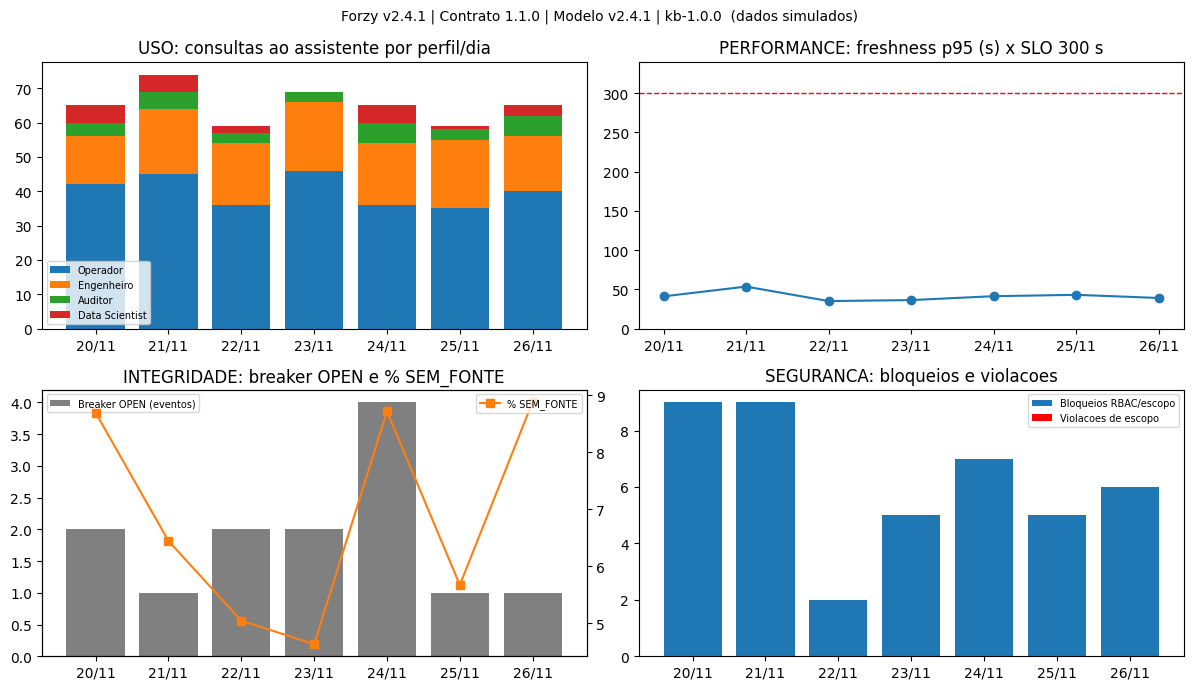

In [18]:
rng = np.random.default_rng(7)
dias = pd.date_range("2026-11-20", periods=7, freq="D").strftime("%d/%m")
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
# Uso
bottom = np.zeros(7)
for perfil, base in [("Operador", 40), ("Engenheiro", 18), ("Auditor", 4), ("Data Scientist", 3)]:
    v = rng.poisson(base, 7); ax[0, 0].bar(dias, v, bottom=bottom, label=perfil); bottom += v
ax[0, 0].set_title("USO: consultas ao assistente por perfil/dia"); ax[0, 0].legend(fontsize=7)
# Performance
fresh = 40 + rng.normal(0, 6, 7); ax[0, 1].plot(dias, fresh, marker="o"); ax[0, 1].axhline(300, color="red", ls="--", lw=1)
ax[0, 1].set_title("PERFORMANCE: freshness p95 (s) x SLO 300 s"); ax[0, 1].set_ylim(0, 340)
# Integridade
abertos = rng.poisson(2, 7); sem_fonte = rng.uniform(3, 9, 7)
ax[1, 0].bar(dias, abertos, color="gray", label="Breaker OPEN (eventos)"); ax2 = ax[1, 0].twinx()
ax2.plot(dias, sem_fonte, color="tab:orange", marker="s", label="% SEM_FONTE"); ax[1, 0].set_title("INTEGRIDADE: breaker OPEN e % SEM_FONTE")
ax[1, 0].legend(loc="upper left", fontsize=7); ax2.legend(loc="upper right", fontsize=7)
# Seguranca
bloq = rng.poisson(5, 7); viol = rng.poisson(0.4, 7)
ax[1, 1].bar(dias, bloq, label="Bloqueios RBAC/escopo"); ax[1, 1].bar(dias, viol, color="red", label="Violacoes de escopo")
ax[1, 1].set_title("SEGURANCA: bloqueios e violacoes"); ax[1, 1].legend(fontsize=7)
fig.suptitle(f"Forzy v2.4.1 | Contrato {contract['contract']['version']} | Modelo {MODELO_ML} | {KB_VERSION}  (dados simulados)", fontsize=10)
plt.tight_layout(); plt.show()

In [19]:
# Exporta evidencias para anexar ao repositorio / documento
log_df.to_csv("audit_log_assistente_simulado.csv", index=False)
tabela_slo.to_csv("slo_simulado.csv", index=False)
print("Arquivos gerados: metric_contract.yaml, audit_log_assistente_simulado.csv, slo_simulado.csv")

Arquivos gerados: metric_contract.yaml, audit_log_assistente_simulado.csv, slo_simulado.csv
